### Performing LOO-PIT on Field-Level MCMCs with Fixed Initial Conditions

This code book performs LOO-PIT analysis on an MCMC chain provided by Hugo Simon and Arnaud Di Mattia (University of Paris-Saclay). 
The chains are Field-Level inference chains of galaxy density counts over a 32 x 32 x 32 voxel space.
These chains specifically have their initial conditions fixed and only samples over the cosmological parameters. 

First we load the necessary packages

In [1]:
Pkg.instantiate()
Pkg.resolve()

  No Changes to `~/.julia/v1.11/Project.toml`
  No Changes to `~/.julia/v1.11/Manifest.toml`


In [2]:
# Pkg.add("Turing")
# Pkg.add("Capse")
# Pkg.add("NPZ")
# Pkg.add(url="https://github.com/JuliaCosmologicalLikelihoods/PlanckLite.jl")
# Pkg.add("BenchmarkTools")
# Pkg.add("Plots")
# Pkg.add("Optim")
# Pkg.add("ForwardDiff")
# Pkg.add("LinearAlgebra")
# Pkg.add("Pathfinder")
# Pkg.add("MicroCanonicalHMC")
# Pkg.add("Transducers")
# Pkg.add("StatsPlots")
# Pkg.add("PairPlots")
# Pkg.add("LaTeXStrings")
# Pkg.add("MCMCChains")
# Pkg.add("PSIS")
# Pkg.add("ArviZ")
# Pkg.add("ArviZPythonPlots")
# Pkg.add("IrrationalConstants")
# Pkg.add("DimensionalData")
# Pkg.add("Statistics")

In [3]:
# using Turing
# using Capse
using NPZ
# # using PlanckLite
# using BenchmarkTools
# using Plots
# using Optim
# using ForwardDiff
# using Pathfinder
# #using MicroCanonicalHMC
# #using Transducers
# using StatsPlots
# #using PairPlots
# #using LaTeXStrings
# #using CairoMakie
# using MCMCChains
using PSIS
# include("utils.jl");
using ArviZ
using ArviZPythonPlots
using LinearAlgebra
using IrrationalConstants
using DimensionalData
using Statistics
using Plots

### PSIS

We begin by running Pareto Smoothed Importance Sampling (PSIS) on the full voxels, and storing the results.

The chains provided are a single file, which is loaded below. 

In [4]:
f = npzread("/Users/ethansmith/Desktop/Waterloo/Masters/LOO-PIT/loop_it_in_the_field/data_hugo/fixed_ic/logdf_mesh.npz")

Dict{String, Array{Float64, 5}} with 2 entries:
  "logcdf_mesh" => [-0.422306 -0.432131 … -0.41779 -0.429081; -0.428338 -0.4283…
  "logpdf_mesh" => [-3.66273 -3.65593 … -3.66599 -3.658; -3.65851 -3.65847 … -3…

For the process of PSIS, we need the logpdf_mesh field, which are the log probabilities of each voxel that the chain has determined by fitting the model to the full data set. That is, the logpdf_mesh represent $p(y | \theta)$

In [35]:
f["logpdf_mesh"]

4×512×32×32×32 Array{Float64, 5}:
[:, :, 1, 1, 1] =
 -3.66273  -3.65593  -3.65958  -3.66154  …  -3.65461  -3.66599  -3.658
 -3.65851  -3.65847  -3.65608  -3.66237     -3.66681  -3.66477  -3.65942
 -3.66151  -3.65806  -3.66311  -3.65798     -3.65623  -3.65636  -3.66537
 -3.65984  -3.6677   -3.6602   -3.66124     -3.65894  -3.66515  -3.66617

[:, :, 2, 1, 1] =
 -3.5853   -3.58419  -3.58473  -3.5849   …  -3.58398  -3.58606  -3.58427
 -3.58441  -3.58458  -3.58407  -3.58544     -3.58595  -3.5854   -3.58462
 -3.58493  -3.58427  -3.58529  -3.58425     -3.58409  -3.58414  -3.58604
 -3.58479  -3.58581  -3.58466  -3.58488     -3.58461  -3.58561  -3.58598

[:, :, 3, 1, 1] =
 -3.84162  -3.83027  -3.83761  -3.84832  …  -3.82973  -3.84179  -3.84578
 -3.84308  -3.83449  -3.83847  -3.8327      -3.85314  -3.85658  -3.84145
 -3.84652  -3.84641  -3.84558  -3.84685     -3.83904  -3.83739  -3.83683
 -3.83735  -3.86705  -3.84697  -3.84644     -3.83726  -3.85148  -3.84644

;;; … 

[:, :, 30, 1, 1] =
 -3.7085

Each of the 32 x 32 x 32 voxels has 4 x 512 delta logdensities from the chain corresponding to that voxel.

Below, we create an array of vectors called logpdf_mesh to store the data from the file. Each of the 32 x 32 x 32 elements has a vector corresponding to a single voxel, and the vector holds the log probability values.

In [29]:
logpdf_mesh = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    logpdf_mesh[i,j,k] = []
end

for i in 1:32, j in 1:32, k in 1:32
    append!(logpdf_mesh[i,j,k], vec(f["logpdf_mesh"][:,:,i,j,k]))
end

Thus, log_pdf is a data object representing the 32 x 32 x 32 voxels, with each element holding 2048 log probability values collected from the file.

In [8]:
logpdf_mesh

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-3.66273, -3.65851, -3.66151, -3.65984, -3.65593, -3.65847, -3.65806, -3.6677, -3.65958, -3.65608  …  -3.65623, -3.65894, -3.66599, -3.66477, -3.65636, -3.66515, -3.658, -3.65942, -3.66537, -3.66617]     …  [-3.84296, -3.83876, -3.84301, -3.83861, -3.83232, -3.8363, -3.8392, -3.85543, -3.8384, -3.83479  …  -3.83512, -3.83761, -3.84651, -3.84936, -3.8348, -3.84835, -3.83895, -3.83931, -3.84444, -3.84802]
 [-3.5853, -3.58441, -3.58493, -3.58479, -3.58419, -3.58458, -3.58427, -3.58581, -3.58473, -3.58407  …  -3.58409, -3.58461, -3.58606, -3.5854, -3.58414, -3.58561, -3.58427, -3.58462, -3.58604, -3.58598]       [-3.62951, -3.63081, -3.63172, -3.62824, -3.62602, -3.62731, -3.63226, -3.63932, -3.62839, -3.62932  …  -3.62953, -3.62835, -3.62905, -3.63537, -3.62883, -3.63317, -3.63201, -3.62998, -3.62715, -3.63092]
 [-3.84162, -3.84308, -3.84652, -3.83735, -3.83027, -3.83449, -3.84641, -3.86705, -3.83761, -3.83847  …  -3.83904, -3.83726, -3.84

In [30]:
logpdf_mesh[3,16,4]

2048-element Vector{Float64}:
 -4.565168857605628
 -4.558729988483616
 -4.559683635492516
 -4.5650916656926235
 -4.566006772012023
 -4.565723117497284
 -4.555478010316706
 -4.5509520817992
 -4.564547871722637
 -4.559418892974969
 -4.562415705304059
 -4.557708926945701
 -4.558276181985038
  ⋮
 -4.5647591731627895
 -4.560815560828795
 -4.559143550168367
 -4.5640321306907605
 -4.569000642415665
 -4.5556355294572475
 -4.560665402698266
 -4.560145552712189
 -4.5559059114109655
 -4.561198984431772
 -4.572333541443412
 -4.565435718436226

Next, we perform Pareto Smoothed Importance Sampling (PSIS) on each voxel's vector of log pdf probabilities.

In [10]:
psis_result = Array{PSISResult{Float64, Vector{Float64}, Int64, Int64, PSIS.GeneralizedPareto{Float64}}}(undef, 32, 32, 32);
for i in 1:32, j in 1:32, k in 1:32
    psis_result[i, j, k] = psis(-logpdf_mesh[i,j,k])
end

The importance weights and the pareto shape values are stored in their own 32 x 32 x 32 arrays so that the PSIS weights and the pareto shape value can be recalled easily for each voxel if needed.

In [31]:
psis_weights = Array{Vector{Float64}}(undef, 32, 32, 32)
for i in 1:32, j in 1:32, k in 1:32
    psis_weights[i,j,k] = psis_result[i,j,k].weights
end

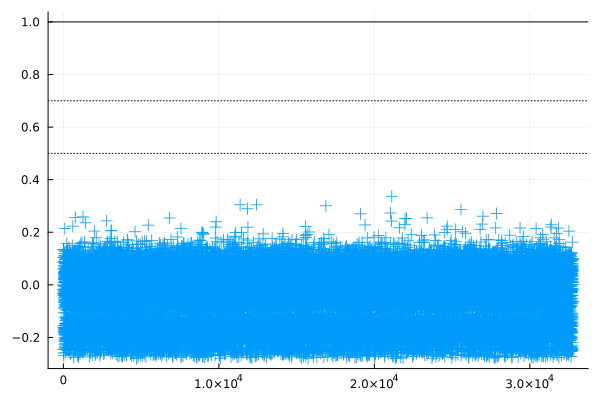

In [12]:
pareto_shapes = []
for i in 1:32, j in 1:32, k in 1:32
    append!(pareto_shapes, psis_result[i,j,k].pareto_shape)
end

psis_plot = Plots.scatter(pareto_shapes; marker =:+, markersize=6, legend = false, linewidth=2)
hline!([0.5,0.7], linestyle=:dot, color =:black)
hline!([1.0], linestyle=:solid, color=:black)

The plot above is of the Pareto shape parameters from PSIS. Because the shape parameters are all under the threshhold of 0.5, this informs that the importance sampling is well-behaved and reliable for probability reweighting in the Leave One Out approach.

Now that we know the weights are reliable, we can proceed with the LOO-PIT analysis. The PSIS weights inform how to reweight $p(y | \theta)$ determined by the MCMC logpdf_mesh field, into $p(y_{-i} | \theta)$, the LOO probability density. 

First load the logcdf_mesh field from the MCMC chain file. Similar to logpdf_mesh, this field has contains 4 x 512 samples corresponding to the CDF of that particular voxel. It is stored below in an array with each voxel having an array of all CDF samples

In [36]:
logcdf_mesh = Array{Vector{Float64}}(undef, 32, 32, 32)

for i in 1:32, j in 1:32, k in 1:32
    logcdf_mesh[i,j,k] = []
end

for i in 1:32, j in 1:32, k in 1:32
    append!(logcdf_mesh[i,j,k], vec(f["logcdf_mesh"][:,:,i,j,k]))
end

In [37]:
logcdf_mesh

32×32×32 Array{Vector{Float64}, 3}:
[:, :, 1] =
 [-0.422306, -0.428338, -0.424026, -0.426407, -0.432131, -0.428395, -0.428989, -0.415467, -0.426785, -0.431908  …  -0.431685, -0.427707, -0.41779, -0.419463, -0.43149, -0.418943, -0.429081, -0.42702, -0.418635, -0.417543]                        …  [-0.268234, -0.270587, -0.268201, -0.270672, -0.274275, -0.271984, -0.270341, -0.261431, -0.270792, -0.27285  …  -0.272663, -0.271244, -0.266266, -0.264703, -0.272845, -0.265258, -0.27048, -0.270282, -0.267412, -0.265435]
 [-0.636253, -0.6463, -0.640209, -0.641786, -0.649194, -0.644266, -0.648162, -0.631275, -0.642457, -0.650892  …  -0.650675, -0.643852, -0.629044, -0.635273, -0.649951, -0.633223, -0.648157, -0.643781, -0.629196, -0.629767]                          [-0.477551, -0.474965, -0.473171, -0.480113, -0.48471, -0.482026, -0.472127, -0.459086, -0.479809, -0.477924  …  -0.477506, -0.479883, -0.478463, -0.466239, -0.478911, -0.470377, -0.472613, -0.476598, -0.482357, -0.474741]
 [-0.268983

The CDF values are then able to be systemically reweighted by the PSIS weights in order to obtain the LOO-PIT final values.

In [25]:
loo_pit = Array{Float64}(undef, 32, 32, 32)

for i in 1:32
    for j in 1:32
        for k in 1:32
            loo_pit[i,j,k] = dot(psis_weights[i,j,k], exp.(logcdf_mesh[i,j,k]))
        end
    end
end

Plotting the LOO-PIT values in a histogram, we see the approximately uniform distribution of values as expected from a MCMC sampling based on a strong model.

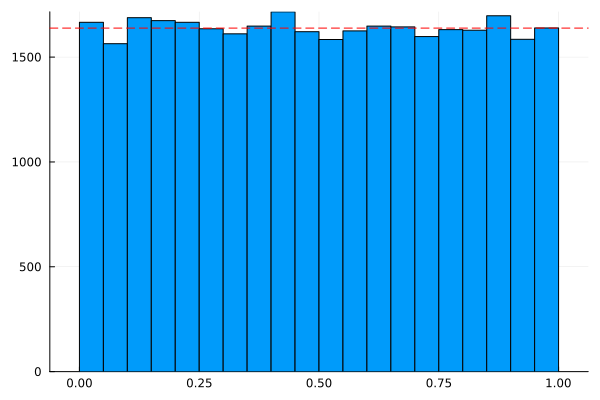

In [26]:
Plots.histogram(vec(loo_pit), legend=false)
hline!([length(loo_pit) / 20], color=:red, linestyle=:dash)